In [3]:
import xarray as xr
from pathlib import Path

file_path = Path(r"C:\Users\Mkosh\OneDrive\Desktop\Project\AgriRain-ML\data\raw\rainfall\RF25_ind2024_rfp25.nc")
print("File Exists:",file_path.exists())

File Exists: True


In [4]:
ds=xr.open_dataset(file_path)
ds

<xarray.Dataset> Size: 26MB
Dimensions:    (TIME: 366, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

In [5]:
ds["RAINFALL"].attrs

{'long_name': 'Rainfall', 'units': 'mm', 'history': 'From ind2024_rfp25.grd'}

In [7]:
print("First date:", ds.TIME.values[0])
print("Last date:", ds.TIME.values[-1])

print("Minimum latitude:", ds.LATITUDE.min().values)
print("Maximum latitude:", ds.LATITUDE.max().values)

print("Minimum longitude:", ds.LONGITUDE.min().values)
print("Maximum longitude:", ds.LONGITUDE.max().values)

First date: 2024-01-01T00:00:00.000000000
Last date: 2024-12-31T00:00:00.000000000
Minimum latitude: 6.5
Maximum latitude: 38.5
Minimum longitude: 66.5
Maximum longitude: 100.0


In [8]:
rainfall = ds["RAINFALL"]

print("Total observations:", rainfall.size)
print("Missing values:", rainfall.isnull().sum().values)
print("Minimum rainfall:", rainfall.min().values)
print("Maximum rainfall:", rainfall.max().values)
print("Mean rainfall:", rainfall.mean().values)

Total observations: 6373890
Missing values: 4557066
Minimum rainfall: 0.0
Maximum rainfall: 660.5492
Mean rainfall: 3.320558


In [9]:
total = rainfall.size
missing = rainfall.isnull().sum().values
valid = total - missing

print("Missing percentage:", (missing / total) * 100)
print("Valid percentage:", (valid / total) * 100)

Missing percentage: 71.49583692219352
Valid percentage: 28.50416307780649


In [10]:
missing_map = rainfall.isnull().mean(dim="TIME")

print(missing_map)

<xarray.DataArray 'RAINFALL' (LATITUDE: 129, LONGITUDE: 135)> Size: 139kB
array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(129, 135))
Coordinates:
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2024_rfp25.grd


In [1]:
import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")

Matplotlib installed successfully!


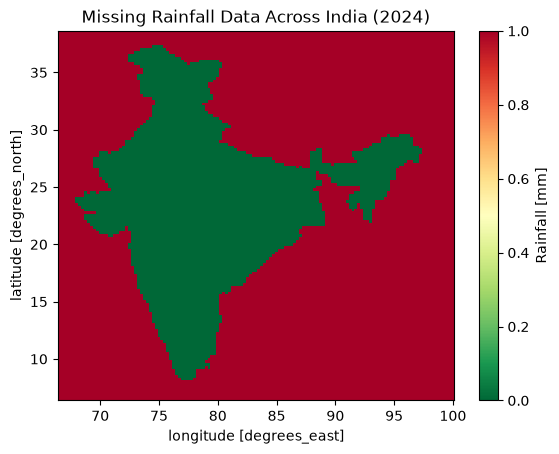

In [13]:
import matplotlib.pyplot as plt

missing_map.plot(
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1
)

plt.title("Missing Rainfall Data Across India (2024)")
plt.show()

In [14]:
print("Grid points with no missing days:",
      (missing_map == 0).sum().values)

print("Grid points with some missing days:",
      ((missing_map > 0) & (missing_map < 1)).sum().values)

print("Grid points with all days missing:",
      (missing_map == 1).sum().values)

Grid points with no missing days: 4964
Grid points with some missing days: 0
Grid points with all days missing: 12451


In [15]:
print("Negative rainfall observations:",
      (rainfall < 0).sum().values)

print("Zero rainfall observations:",
      (rainfall == 0).sum().values)

print("Positive rainfall observations:",
      (rainfall > 0).sum().values)

Negative rainfall observations: 0
Zero rainfall observations: 1294954
Positive rainfall observations: 521870


In [16]:
#Verify all Rainfall Files
from pathlib import Path

rainfall_dir = Path("../data/raw/rainfall")

rainfall_files = sorted(rainfall_dir.glob("*.nc"))

print("Total rainfall files:", len(rainfall_files))
print("First file:", rainfall_files[0].name)
print("Last file:", rainfall_files[-1].name)

Total rainfall files: 124
First file: RF25_ind1901_rfp25.nc
Last file: RF25_ind2024_rfp25.nc


In [ ]:
#Automated structural audit across all files
import xarray as xr
import pandas as pd

audit_records = []

for file_path in rainfall_files:
    try:
        with xr.open_dataset(file_path) as ds:

            audit_records.append({
                "File": file_path.name,
                "Variables": list(ds.data_vars),
                "Dimensions": dict(ds.sizes),
                "Start_Date": str(ds["TIME"].values[0])[:10],
                "End_Date": str(ds["TIME"].values[-1])[:10],
                "Latitude_Count": ds.sizes["LATITUDE"],
                "Longitude_Count": ds.sizes["LONGITUDE"],
                "Status": "Success"
            })

    except Exception as e:
        audit_records.append({
            "File": file_path.name,
            "Status": f"Error: {e}"
        })

audit_df = pd.DataFrame(audit_records)

print("Files inspected:", len(audit_df))
print("Successful:", (audit_df["Status"] == "Success").sum())
print("Failed:", (audit_df["Status"] != "Success").sum())

Files inspected: 124
Successful: 124
Failed: 0


In [ ]:
#Compare dimensions and variables across all files
print("Variable consistency:")
print(audit_df["Variables"].value_counts())

print("\nDimension consistency:")
print(audit_df["Dimensions"].value_counts())

print("\nLatitude counts:")
print(audit_df["Latitude_Count"].value_counts())

print("\nLongitude counts:")
print(audit_df["Longitude_Count"].value_counts())

Variable consistency:
Variables
[RAINFALL]    124
Name: count, dtype: int64

Dimension consistency:
Dimensions
{'TIME': 365, 'LATITUDE': 129, 'LONGITUDE': 135}    93
{'TIME': 366, 'LATITUDE': 129, 'LONGITUDE': 135}    31
Name: count, dtype: int64

Latitude counts:
Latitude_Count
129    124
Name: count, dtype: int64

Longitude counts:
Longitude_Count
135    124
Name: count, dtype: int64


In [ ]:
#Check Date Coverage across all files
audit_df["Year"] = audit_df["File"].str.extract(r"ind(\d{4})").astype(int)

audit_df["Expected_Days"] = audit_df["Year"].apply(
    lambda year: 366 if pd.Timestamp(year=year, month=12, day=31).is_leap_year else 365
)

audit_df["Actual_Days"] = audit_df["Dimensions"].apply(
    lambda dimensions: dimensions["TIME"]
)

audit_df["Date_Check"] = audit_df["Expected_Days"] == audit_df["Actual_Days"]

print("Years covered:", audit_df["Year"].min(), "-", audit_df["Year"].max())
print("Unique years:", audit_df["Year"].nunique())
print("Incorrect day counts:", (~audit_df["Date_Check"]).sum())
print("Duplicate years:", audit_df["Year"].duplicated().sum())

Years covered: 1901 - 2024
Unique years: 124
Incorrect day counts: 0
Duplicate years: 0


In [ ]:
#Check coordinate consistency across all files
reference_file = rainfall_files[0]

with xr.open_dataset(reference_file) as reference_ds:
    reference_lat = reference_ds["LATITUDE"].values.copy()
    reference_lon = reference_ds["LONGITUDE"].values.copy()

coordinate_results = []

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        same_lat = (ds["LATITUDE"].values == reference_lat).all()
        same_lon = (ds["LONGITUDE"].values == reference_lon).all()

        coordinate_results.append({
            "File": file_path.name,
            "Latitude_Match": same_lat,
            "Longitude_Match": same_lon
        })

coordinate_df = pd.DataFrame(coordinate_results)

print("Latitude mismatches:", (~coordinate_df["Latitude_Match"]).sum())
print("Longitude mismatches:", (~coordinate_df["Longitude_Match"]).sum())

Latitude mismatches: 0
Longitude mismatches: 0


In [ ]:
#Check for missing values across all files
missing_results = []

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        rainfall = ds["RAINFALL"]

        total = rainfall.size
        missing = int(rainfall.isnull().sum().compute().item())
        valid = total - missing

        missing_results.append({
            "Year": int(file_path.name[8:12]),
            "Total_Observations": total,
            "Missing_Observations": missing,
            "Valid_Observations": valid,
            "Missing_Percentage": missing / total * 100
        })

missing_df = pd.DataFrame(missing_results)

print("Overall missing percentage:",
      missing_df["Missing_Observations"].sum()
      / missing_df["Total_Observations"].sum() * 100)

print("\nHighest missing percentage:")
print(missing_df.nlargest(5, "Missing_Percentage")[
    ["Year", "Missing_Percentage"]
])

print("\nLowest missing percentage:")
print(missing_df.nsmallest(5, "Missing_Percentage")[
    ["Year", "Missing_Percentage"]
])

Overall missing percentage: 71.49584693813324

Highest missing percentage:
     Year  Missing_Percentage
122  2023           71.497080
0    1901           71.495837
1    1902           71.495837
2    1903           71.495837
3    1904           71.495837

Lowest missing percentage:
   Year  Missing_Percentage
0  1901           71.495837
1  1902           71.495837
2  1903           71.495837
3  1904           71.495837
4  1905           71.495837


In [ ]:
#Check whether the missing-value pattern is spatially consistent across all files
spatial_results = []

reference_mask = None

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        rainfall = ds["RAINFALL"]

        # Classify each grid cell
        missing_mask = rainfall.isnull().all(dim="TIME")
        valid_mask = rainfall.notnull().all(dim="TIME")
        partial_mask = ~(missing_mask | valid_mask)

        missing_grid = missing_mask.values
        valid_grid = valid_mask.values
        partial_grid = partial_mask.values

        current_mask = missing_grid

        if reference_mask is None:
            reference_mask = current_mask.copy()

        spatial_results.append({
            "Year": int(file_path.name[8:12]),
            "Always_Missing": int(missing_grid.sum()),
            "Always_Valid": int(valid_grid.sum()),
            "Partially_Missing": int(partial_grid.sum()),
            "Mask_Mismatches": int(
                (current_mask != reference_mask).sum()
            )
        })

spatial_df = pd.DataFrame(spatial_results)

print("First year spatial pattern:")
print(spatial_df.iloc[0])

print("\nLast year spatial pattern:")
print(spatial_df.iloc[-1])

print("\nMaximum mask mismatches:",
      spatial_df["Mask_Mismatches"].max())

First year spatial pattern:
Year                  1901
Always_Missing       12451
Always_Valid          4964
Partially_Missing        0
Mask_Mismatches          0
Name: 0, dtype: int64

Last year spatial pattern:
Year                  2024
Always_Missing       12451
Always_Valid          4964
Partially_Missing        0
Mask_Mismatches          0
Name: 123, dtype: int64

Maximum mask mismatches: 0


In [ ]:
#Check Rainfall values across all files
value_results = []

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        rainfall = ds["RAINFALL"]

        negative = int((rainfall < 0).sum().compute().item())
        zero = int((rainfall == 0).sum().compute().item())
        positive = int((rainfall > 0).sum().compute().item())

        minimum = float(rainfall.min().compute().item())
        maximum = float(rainfall.max().compute().item())

        value_results.append({
            "Year": int(file_path.name[8:12]),
            "Negative": negative,
            "Zero": zero,
            "Positive": positive,
            "Minimum": minimum,
            "Maximum": maximum
        })

values_df = pd.DataFrame(value_results)

print("Total negative observations:", values_df["Negative"].sum())
print("Total zero observations:", values_df["Zero"].sum())
print("Total positive observations:", values_df["Positive"].sum())

print("\nHighest rainfall observations:")
print(values_df.nlargest(5, "Maximum")[["Year", "Maximum"]])

print("\nLowest rainfall observations:")
print(values_df.nsmallest(5, "Minimum")[["Year", "Minimum"]])

Total negative observations: 0
Total zero observations: 159661030
Total positive observations: 65163415

Highest rainfall observations:
     Year     Maximum
121  2022  979.144775
81   1982  939.446167
73   1974  898.934998
100  2001  822.063293
94   1995  821.665833

Lowest rainfall observations:
   Year  Minimum
0  1901      0.0
1  1902      0.0
2  1903      0.0
3  1904      0.0
4  1905      0.0


In [ ]:
#Investigate extreme rainfall values across all files
extreme_results = []

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        rainfall = ds["RAINFALL"]

        max_value = float(rainfall.max().compute().item())

        location = rainfall.where(
            rainfall == max_value,
            drop=True
        ).stack(
            point=("TIME", "LATITUDE", "LONGITUDE")
        ).dropna("point")

        for point in location["point"].values:
            time, lat, lon = point

            extreme_results.append({
                "Year": int(file_path.name[8:12]),
                "Rainfall_mm": max_value,
                "Date": str(time)[:10],
                "Latitude": float(lat),
                "Longitude": float(lon)
            })

extreme_df = pd.DataFrame(extreme_results)

extreme_df.sort_values(
    "Rainfall_mm",
    ascending=False
).head(10)

,Year,Rainfall_mm,Date,Latitude,Longitude
121,2022,979.144775,2022-06-17,25.25,91.25
81,1982,939.446167,1982-08-04,25.25,91.25
73,1974,898.934998,1974-09-13,25.25,91.25
100,2001,822.063293,2001-10-06,22.25,79.00
94,1995,821.665833,1995-06-15,25.25,91.25
40,1941,802.855713,1941-07-02,20.50,73.00
83,1984,795.649170,1984-09-23,26.25,90.25
90,1991,747.723572,1991-07-22,21.75,87.75
104,2005,732.457397,2005-07-27,19.25,72.75
64,1965,722.392456,1965-08-04,28.00,79.25


In [ ]:
#Investigate the highest rainfall observation across all files
with xr.open_dataset(
    rainfall_dir / "RF25_ind2022_rfp25.nc"
) as ds:

    day = ds["RAINFALL"].sel(TIME="2022-06-17")

    neighborhood = day.where(
        (day.LATITUDE >= 25.0) &
        (day.LATITUDE <= 25.5) &
        (day.LONGITUDE >= 91.0) &
        (day.LONGITUDE <= 91.5),
        drop=True
    )

    print(neighborhood.to_pandas())

LONGITUDE       91.00       91.25       91.50
LATITUDE                                     
25.00             NaN         NaN         NaN
25.25      919.281799  979.144775  891.513550
25.50      862.294006  751.101074  128.187012


In [ ]:
#Check annual rainfall statistics across all files
annual_stats = []

for file_path in rainfall_files:
    with xr.open_dataset(file_path) as ds:

        rainfall = ds["RAINFALL"]

        annual_stats.append({
            "Year": int(file_path.name[8:12]),
            "Mean_Rainfall": float(rainfall.mean().compute().item()),
            "Max_Rainfall": float(rainfall.max().compute().item())
        })

annual_stats_df = pd.DataFrame(annual_stats)

print("Lowest annual mean:")
print(annual_stats_df.nsmallest(5, "Mean_Rainfall"))

print("\nHighest annual mean:")
print(annual_stats_df.nlargest(5, "Mean_Rainfall"))

Lowest annual mean:
     Year  Mean_Rainfall  Max_Rainfall
17   1918       2.498414    314.717529
71   1972       2.509495    641.245667
64   1965       2.530704    722.392456
101  2002       2.557512    594.873596
4    1905       2.640326    358.852936

Highest annual mean:
    Year  Mean_Rainfall  Max_Rainfall
16  1917       3.789405    401.033966
89  1990       3.717152    630.000061
55  1956       3.612927    444.500000
32  1933       3.595723    327.168579
60  1961       3.594713    469.312469
